In [2]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Perceptron
from sklearn.metrics import (
accuracy_score,
average_precision_score,
classification_report,
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,
fbeta_score,
precision_score,
precision_recall_curve,
PrecisionRecallDisplay,
recall_score,
roc_auc_score,
roc_curve,
RocCurveDisplay
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from src.config import DADOS_LIMPOS
from src.models import RANDOM_STATE

In [3]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [4]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

In [5]:
le = LabelEncoder()

y = le.fit_transform(y)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

In [7]:
np.bincount(y_train) / len(y_train)

array([0.62676056, 0.37323944])

In [8]:
np.bincount(y_test) / len(y_test)

array([0.62937063, 0.37062937])

In [9]:
clf = Perceptron()

clf.fit(X_train, y_train)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [10]:
y_pred = clf.predict(X_test)

In [11]:
clf.score(X_test, y_test)

0.9020979020979021

O `score` do classificador retorna a acurácia do modelo que éa proporção de predições corretas feitas pelo modelo. Podemos calcular a acurácia comparando as predições feitas pelo modelo com as respostas corretas. A acurácia é dada por:


 $acurácia = \frac{número\ de\ predições\ corretas}{número\ total\ de predições}$


Uma acurácia de 1 significa que o modelo fez todas as predições corretas, enquanto uma acurácia de 0 significa que o modelo fez todas as predições erradas.


In [12]:
print(y_test[:20])
print(y_pred[:20])

[1 0 1 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1]
[1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0]


No caso há uma acurácia de 90.2%

In [13]:
accuracy_score(y_test, y_pred)

0.9020979020979021

Além de a acurácia não ser uma métrica perfeita para avaliar a qualiade de um modelo caso uma base de dados seja desbalanceada, também trata todos os erros da mesma forma, o que pode ser indesejado em alguns casos em que um um determindado resultado errado é muito mais grave que outros, como o caso de tetes de doenças que são falsos negativos.


# Matriz de confusão

A matriz de confusão é uma tabela que mostra o número de predições corretas e incorretas feitas pelo modelo.

In [15]:
le.classes_

array(['B', 'M'], dtype=object)

In [17]:
np.bincount(y_test)

array([90, 53])

In [ ]:
confusion_matrix(y_test, y_pred,)

array([[89,  1],
       [13, 40]])

In [19]:
pd.DataFrame(confusion_matrix(y_test, y_pred), 
             index=le.classes_, 
             columns=le.classes_)

,B,M
B,89,1
M,13,40


In [ ]:
y_test == y_pred

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True,  True,
        True, False,  True,  True,  True,  True, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False,  True,  True,
        True,  True,

In [ ]:
confusion_matrix(y_test, y_pred,normalize='all')

array([[0.62237762, 0.00699301],
       [0.09090909, 0.27972028]])

In [22]:
confusion_matrix(y_test, y_pred,normalize='true')

array([[0.98888889, 0.01111111],
       [0.24528302, 0.75471698]])

In [23]:
confusion_matrix(y_test, y_pred,normalize='pred')

array([[0.87254902, 0.02439024],
       [0.12745098, 0.97560976]])

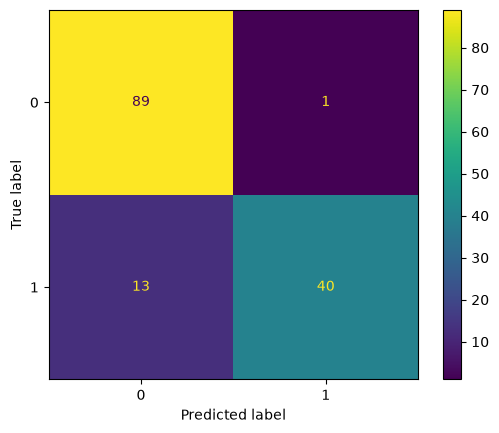

In [25]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot()

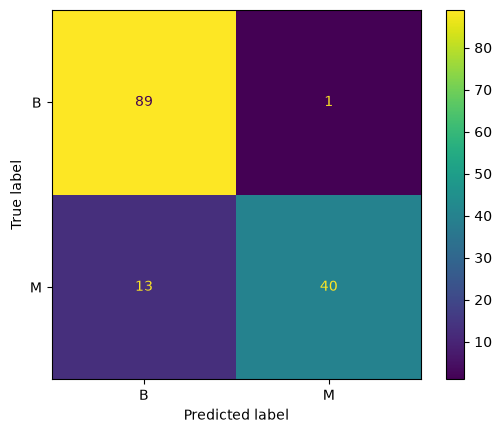

In [26]:
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot()

# Recall
Uma métrica que pode ser usada para avaliar a qualidade de um modelo de classificação, medindo quantos casos positivos foram classificados corretamente por ele.

$recall = \frac{TP}{P} = \frac{TP}{TP+FN}$

In [27]:
recall_score(y_test, y_pred)

0.7547169811320755

# Precision
A precisão é a proporção de exemplos classificados como positivos que são realmente positivos.

$precision = \frac{TP}{Pred\ P} = \frac{TP}{TP+FP}$

In [28]:
precision_score(y_test, y_pred)

0.975609756097561

# F Score

O F1 Score é a média harmônica entre recall e precision. A média harmônica é usada ao invés da aritimética porque penaliza valores extremos. O F1 Score é dado por:

$F1 \ Score = 2 \cdot \frac{precision\ \cdot \ recall}{precision\ + \ recall}$

Por ser uma média harmônica, o F1 Score é mais sensível a valores baixos de precisão ou recall.
O F1 Score é um caso especial da média $F_\beta$

$F_\beta = (1+\beta^2) \cdot \frac{precision\ \cdot \ recall}{\beta \cdot \ precision\ + \ recall}$

Quando $\beta>1$, o recall tem mais peso na média. Quando $\beta<1$, precision tem mais peso

In [30]:
f1_score(y_test, y_pred)

0.851063829787234

In [31]:
fbeta_score(y_test, y_pred, beta=0.5)

0.9216589861751152

# Curva ROC

A curva ROC (Receiver Operating Characteristic) é a curva que mostra a taxa de verdadeiros positivos (recall) em função da taxa de falsos positivos.  A curva ROC é útil para avaliar a qualidade de um classificador binário em diferentes thersholds. A área sob essa curva é uma métrica que varia entre 0 e 1, em que 0 significa um classificador ruim e 1,um classificador perfeito.

In [32]:
roc_auc = roc_auc_score(y_test, y_pred)
roc_auc

0.8718029350104822

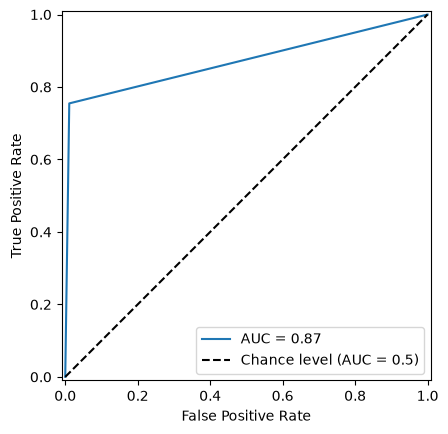

In [37]:
fpr, tpr, limiares = roc_curve(y_test, y_pred)

disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
disp.plot(plot_chance_level=True)

# Curva Precisio-Recall

A curva precision-recall é uma curva que mostra a precisão em função do recall. É útil para avaliar a qualidade de um classificador binário emdiferentes thersholds. A área sob a curva é uma métrica que varia entre 0 e 1, em que 0 significa um classificador ruim e 1,um classificador perfeito.

In [38]:
average_precision = average_precision_score(y_test, y_pred)
average_precision

0.8272183407940426

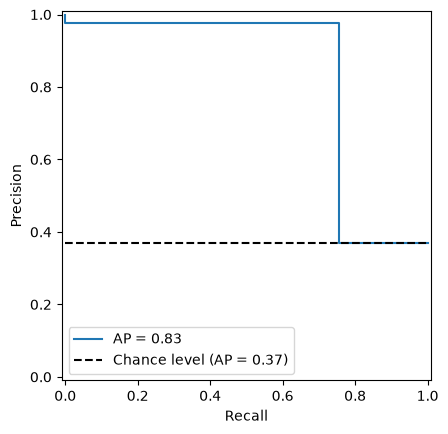

In [43]:
precision, recall, limiares = precision_recall_curve(y_test, y_pred)

disp = PrecisionRecallDisplay(precision=precision, 
                              recall=recall, 
                              average_precision=average_precision,
                              prevalence_pos_label=y_test.mean()
                              )
disp.plot(plot_chance_level=True)

In [47]:
cr = classification_report(y_test, y_pred, target_names=le.classes_)
print(cr)

              precision    recall  f1-score   support

           B       0.87      0.99      0.93        90
           M       0.98      0.75      0.85        53

    accuracy                           0.90       143
   macro avg       0.92      0.87      0.89       143
weighted avg       0.91      0.90      0.90       143

